       Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0             14.0        73         9.5               82.0  partly cloudy   
1             39.0        96         8.5               71.0  partly cloudy   
2             30.0        64         7.0               16.0          clear   
3             38.0        83         1.5               82.0          clear   
4             27.0        74        17.0               66.0       overcast   
...            ...       ...         ...                ...            ...   
13195         10.0        74        14.5               71.0       overcast   
13196         -1.0        76         3.5               23.0         cloudy   
13197         30.0        77         5.5               28.0       overcast   
13198          3.0        76        10.0               94.0       overcast   
13199         -5.0        38         0.0               92.0       overcast   

       Atmospheric Pressure  UV Index  Season  Visibility (km) 

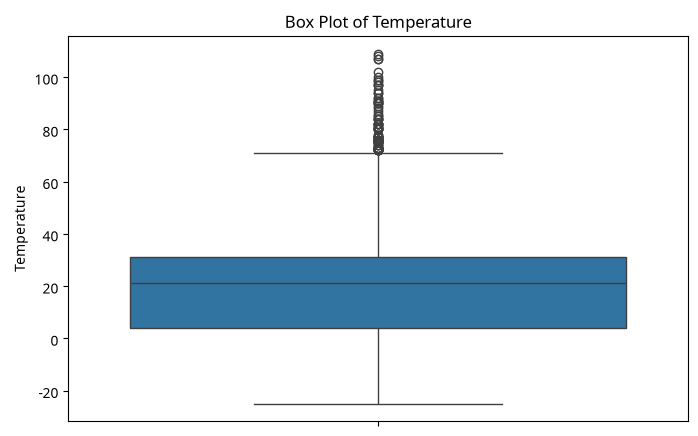

Q1 = 4.0
Q3 = 31.0
IQR = 27.0
Lower Limit = -36.5
Upper Limit = 71.5
Outliers detected using IQR:
       Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
210           78.0        81         8.0               78.0       overcast   
228           73.0        82        47.0              107.0       overcast   
535           80.0        76         3.0               93.0          clear   
709           74.0       101        18.0               76.0  partly cloudy   
730           76.0        91        13.5               82.0  partly cloudy   
...            ...       ...         ...                ...            ...   
12752         90.0        83        15.0               98.0          clear   
12814         72.0        88        12.0               83.0          clear   
12878         95.0        96         1.0               84.0  partly cloudy   
13065         97.0        95         7.5               79.0          clear   
13108         81.0        81        10.5    

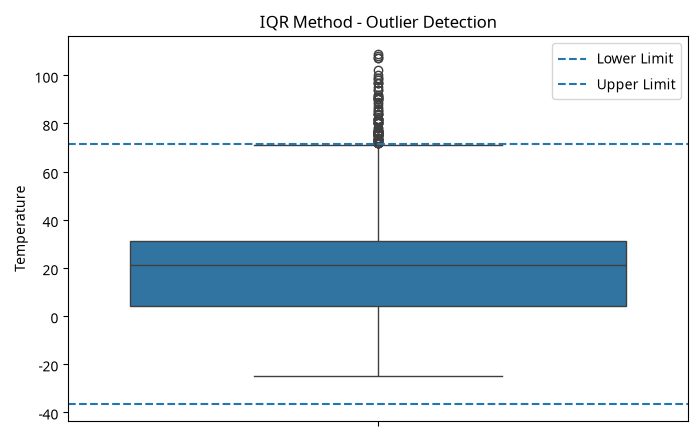

       Temperature  Temperature_IQR_Capped
0             14.0                    14.0
1             39.0                    39.0
2             30.0                    30.0
3             38.0                    38.0
4             27.0                    27.0
...            ...                     ...
13195         10.0                    10.0
13196         -1.0                    -1.0
13197         30.0                    30.0
13198          3.0                     3.0
13199         -5.0                    -5.0

[13200 rows x 2 columns]


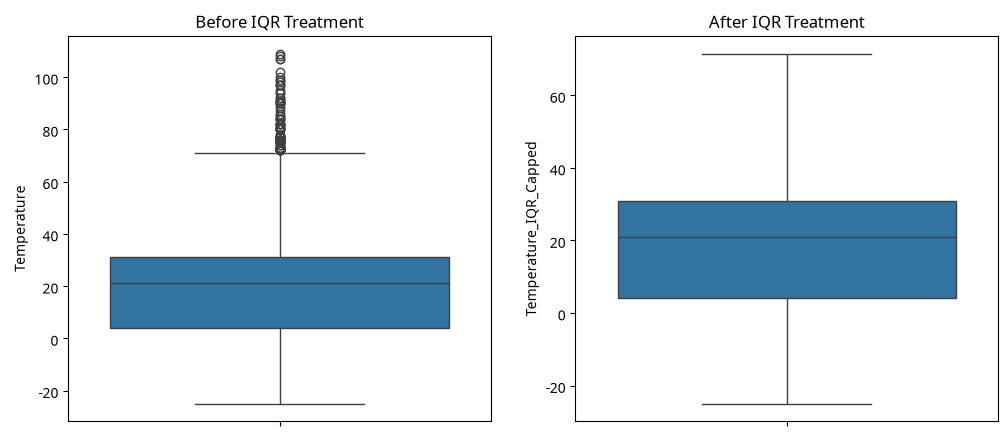

       Temperature   Z_score
0             14.0 -0.294931
1             39.0  1.143035
2             30.0  0.625367
3             38.0  1.085516
4             27.0  0.452811
...            ...       ...
13195         10.0 -0.525006
13196         -1.0 -1.157711
13197         30.0  0.625367
13198          3.0 -0.927636
13199         -5.0 -1.387785

[13200 rows x 2 columns]
Outliers detected using Z-score:
       Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
210           78.0        81         8.0               78.0       overcast   
228           73.0        82        47.0              107.0       overcast   
535           80.0        76         3.0               93.0          clear   
709           74.0       101        18.0               76.0  partly cloudy   
730           76.0        91        13.5               82.0  partly cloudy   
...            ...       ...         ...                ...            ...   
12752         90.0        83        15.0       

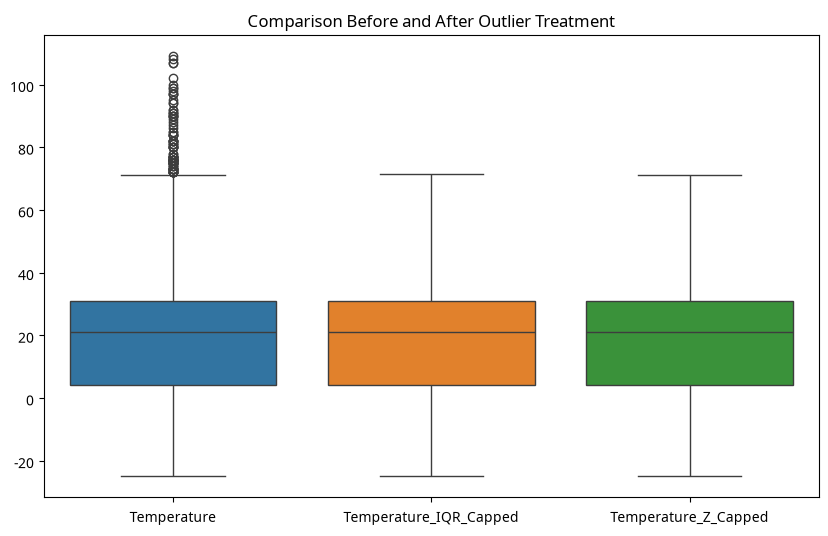

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("weather_classification_data.csv")

print(df)

plt.figure(figsize=(8, 5))

sns.boxplot(y=df["Temperature"])

plt.title("Box Plot of Temperature")
plt.ylabel("Temperature")

plt.show()

Q1 = df["Temperature"].quantile(0.25)

Q3 = df["Temperature"].quantile(0.75)

print("Q1 =", Q1)

print("Q3 =", Q3)

IQR = Q3 - Q1

print("IQR =", IQR)

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)

print("Upper Limit =", upper_limit)

outliers_iqr = df[

    (df["Temperature"] < lower_limit) |

    (df["Temperature"] > upper_limit)

]

print("Outliers detected using IQR:")

print(outliers_iqr)

plt.figure(figsize=(8, 5))

sns.boxplot(y=df["Temperature"])

plt.axhline(lower_limit, linestyle="--", label="Lower Limit")

plt.axhline(upper_limit, linestyle="--", label="Upper Limit")

plt.title("IQR Method - Outlier Detection")

plt.legend()

plt.show()

df["Temperature_IQR_Capped"] = df["Temperature"].clip(lower=lower_limit, upper=upper_limit)

print(df[["Temperature", "Temperature_IQR_Capped"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Temperature"], ax=axes[0])

axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df["Temperature_IQR_Capped"], ax=axes[1])

axes[1].set_title("After IQR Treatment")

plt.show()

df["Z_score"] = stats.zscore(df["Temperature"])

print(df[["Temperature", "Z_score"]])

z_outliers = df[abs(df["Z_score"]) > 3]

print("Outliers detected using Z-score:")

print(z_outliers)

df["Z_Outlier"] = abs(df["Z_score"]) > 3

print(df[["Temperature", "Z_score", "Z_Outlier"]])

mean = df["Temperature"].mean()

std = df["Temperature"].std()

lower_z_limit = mean - 3 * std

upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)

print("Upper Z-score limit =", upper_z_limit)

df["Temperature_Z_Capped"] = df["Temperature"].clip(

    lower=lower_z_limit,

    upper=upper_z_limit

)

print(df[["Temperature", "Temperature_Z_Capped"]])

print(df[["Temperature",

       "Temperature_IQR_Capped",

       "Temperature_Z_Capped"]])

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[

     ["Temperature", "Temperature_IQR_Capped", "Temperature_Z_Capped"]

])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()